# Rossmann Store Sales Prediction

## Imports

In [144]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import opendatasets as od
from IPython.display import display
%matplotlib inline

import plotly.io as pio

# Forces Plotly to save a static fallback image inside the notebook cell
pio.renderers.default = "png"  

## Load and understanding dataset

In [145]:
od.download('https://www.kaggle.com/c/rossmann-store-sales')

Skipping, found downloaded files in ".\rossmann-store-sales" (use force=True to force download)


In [146]:
ross_df = pd.read_csv('./rossmann-store-sales/train.csv', low_memory=False)
ross_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1


In [147]:
store_df = pd.read_csv('./rossmann-store-sales/store.csv')
store_df

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1111,1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1113,1114,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [148]:
merged_df = ross_df.merge(store_df, how='left', on='Store')
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [149]:
merged_df.shape

(1017209, 18)

In [150]:
test_df = pd.read_csv('rossmann-store-sales/test.csv')
merged_test_df = test_df.merge(store_df, how='left', on='Store') 
merged_test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
41084,41085,1112,6,2015-08-01,1.0,0,0,0,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
41085,41086,1113,6,2015-08-01,1.0,0,0,0,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
41086,41087,1114,6,2015-08-01,1.0,0,0,0,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [151]:
# Mostly imp feature are not null but there are few feature which have null values, so either we impute values if possible otherwise we simply exlude them if they aren't that imp.
merged_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  str    
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday               1017209 non-null  str    
 8   SchoolHoliday              1017209 non-null  int64  
 9   StoreType                  1017209 non-null  str    
 10  Assortment                 1017209 non-null  str    
 11  CompetitionDistance        1014567 non-null  float64
 12  CompetitionOpenSinceMonth  693861 non-null   float64
 13  CompetitionOpenSinceYea

In [152]:
merged_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Store,1017209.0,558.429727,321.908651,1.0,280.0,558.0,838.0,1115.0
DayOfWeek,1017209.0,3.998341,1.997391,1.0,2.0,4.0,6.0,7.0
Sales,1017209.0,5773.818972,3849.926175,0.0,3727.0,5744.0,7856.0,41551.0
Customers,1017209.0,633.145946,464.411734,0.0,405.0,609.0,837.0,7388.0
Open,1017209.0,0.830107,0.375539,0.0,1.0,1.0,1.0,1.0
Promo,1017209.0,0.381515,0.485759,0.0,0.0,0.0,1.0,1.0
SchoolHoliday,1017209.0,0.178647,0.383056,0.0,0.0,0.0,0.0,1.0
CompetitionDistance,1014567.0,5430.085652,7715.323700,20.0,710.0,2330.0,6890.0,75860.0
CompetitionOpenSinceMonth,693861.0,7.222866,3.211832,1.0,4.0,8.0,10.0,12.0
CompetitionOpenSinceYear,693861.0,2008.690228,5.992644,1900.0,2006.0,2010.0,2013.0,2015.0


In [153]:
# There are no duplicate enteries in the dataset.
merged_df.duplicated().sum()

np.int64(0)

## Data Cleaning

In [154]:
merged_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  str    
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday               1017209 non-null  str    
 8   SchoolHoliday              1017209 non-null  int64  
 9   StoreType                  1017209 non-null  str    
 10  Assortment                 1017209 non-null  str    
 11  CompetitionDistance        1014567 non-null  float64
 12  CompetitionOpenSinceMonth  693861 non-null   float64
 13  CompetitionOpenSinceYea

In [155]:
print(pd.crosstab(merged_df['Promo2'], merged_df['PromoInterval'].isna()))
print(pd.crosstab(merged_df['Promo2'], merged_df['Promo2SinceWeek'].isna()))

PromoInterval   False   True 
Promo2                       
0                   0  508031
1              509178       0
Promo2SinceWeek   False   True 
Promo2                         
0                     0  508031
1                509178       0


In [156]:
merged_df['Date'] = pd.to_datetime(merged_df.Date)
merged_test_df['Date'] = pd.to_datetime(merged_test_df.Date)
display(merged_df.Date.min(), merged_df.Date.max())
display(merged_test_df.Date.min(), merged_test_df.Date.max())

Timestamp('2013-01-01 00:00:00')

Timestamp('2015-07-31 00:00:00')

Timestamp('2015-08-01 00:00:00')

Timestamp('2015-09-17 00:00:00')

In [157]:
# Since contain's 0, so could be both int or str.
merged_df['StateHoliday'] = merged_df['StateHoliday'].astype('str')
merged_df.StateHoliday.info()

<class 'pandas.Series'>
RangeIndex: 1017209 entries, 0 to 1017208
Series name: StateHoliday
Non-Null Count    Dtype
--------------    -----
1017209 non-null  str  
dtypes: str(1)
memory usage: 8.7 MB


In [158]:
# Basically these columns are null cause Promo2 is 0.
# Therefore we simply replace null with 0.
merged_df[merged_df.Promo2 == 0 & merged_df.Promo2SinceWeek.isna() & merged_df.Promo2SinceYear.isna()]

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
5,6,5,2015-07-31,5651,589,1,1,0,1,a,a,310.0,12.0,2013.0,0,NaN,NaN,NaN
6,7,5,2015-07-31,15344,1414,1,1,0,1,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017201,1108,2,2013-01-01,0,0,0,0,a,1,a,a,540.0,4.0,2004.0,0,NaN,NaN,NaN
1017203,1110,2,2013-01-01,0,0,0,0,a,1,c,c,900.0,9.0,2010.0,0,NaN,NaN,NaN
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN


In [159]:
def ReplaceWithZero(df):
    df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)
    df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)

ReplaceWithZero(merged_df)
ReplaceWithZero(merged_test_df)


In [160]:
display(merged_df.PromoInterval.unique())
merged_df.PromoInterval.isna().value_counts()

<ArrowStringArray>
[nan, 'Jan,Apr,Jul,Oct', 'Feb,May,Aug,Nov', 'Mar,Jun,Sept,Dec']
Length: 4, dtype: str

PromoInterval
False    509178
True     508031
Name: count, dtype: int64

In [161]:
merged_df['PromoInterval'] = merged_df['PromoInterval'].fillna('None').str.strip()
merged_test_df['PromoInterval'] = merged_test_df['PromoInterval'].fillna('None').str.strip()
merged_df.PromoInterval.isna().value_counts()

PromoInterval
False    1017209
Name: count, dtype: int64

In [162]:
merged_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[us]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  str           
 8   SchoolHoliday              1017209 non-null  int64         
 9   StoreType                  1017209 non-null  str           
 10  Assortment                 1017209 non-null  str           
 11  CompetitionDistance        1014567 non-null  flo

In [163]:
merged_df.CompetitionOpenSinceMonth.notna().value_counts()

CompetitionOpenSinceMonth
True     693861
False    323348
Name: count, dtype: int64

In [164]:
merged_df.fillna({'CompetitionOpenSinceMonth': 0}, inplace=True)
merged_df.fillna({'CompetitionOpenSinceYear': 0}, inplace=True)
merged_test_df.fillna({'CompetitionOpenSinceMonth': 0}, inplace=True)
merged_test_df.fillna({'CompetitionOpenSinceYear': 0}, inplace=True)
display(merged_df.info())
display(merged_test_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[us]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  str           
 8   SchoolHoliday              1017209 non-null  int64         
 9   StoreType                  1017209 non-null  str           
 10  Assortment                 1017209 non-null  str           
 11  CompetitionDistance        1014567 non-null  flo

None

<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Id                         41088 non-null  int64         
 1   Store                      41088 non-null  int64         
 2   DayOfWeek                  41088 non-null  int64         
 3   Date                       41088 non-null  datetime64[us]
 4   Open                       41077 non-null  float64       
 5   Promo                      41088 non-null  int64         
 6   StateHoliday               41088 non-null  str           
 7   SchoolHoliday              41088 non-null  int64         
 8   StoreType                  41088 non-null  str           
 9   Assortment                 41088 non-null  str           
 10  CompetitionDistance        40992 non-null  float64       
 11  CompetitionOpenSinceMonth  41088 non-null  float64       
 12  CompetitionOpen

None

In [165]:
# From test set 11 enteries has Open nan, also they belongs to same
merged_test_df[merged_test_df.Open.isna()]

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
479,480,622,4,2015-09-17,NaN,1,0,0,a,c,NaN,0.0,0.0,0,0.0,0.0,None
1335,1336,622,3,2015-09-16,NaN,1,0,0,a,c,NaN,0.0,0.0,0,0.0,0.0,None
2191,2192,622,2,2015-09-15,NaN,1,0,0,a,c,NaN,0.0,0.0,0,0.0,0.0,None
3047,3048,622,1,2015-09-14,NaN,1,0,0,a,c,NaN,0.0,0.0,0,0.0,0.0,None
4759,4760,622,6,2015-09-12,NaN,0,0,0,a,c,NaN,0.0,0.0,0,0.0,0.0,None
5615,5616,622,5,2015-09-11,NaN,0,0,0,a,c,NaN,0.0,0.0,0,0.0,0.0,None
6471,6472,622,4,2015-09-10,NaN,0,0,0,a,c,NaN,0.0,0.0,0,0.0,0.0,None
7327,7328,622,3,2015-09-09,NaN,0,0,0,a,c,NaN,0.0,0.0,0,0.0,0.0,None
8183,8184,622,2,2015-09-08,NaN,0,0,0,a,c,NaN,0.0,0.0,0,0.0,0.0,None
9039,9040,622,1,2015-09-07,NaN,0,0,0,a,c,NaN,0.0,0.0,0,0.0,0.0,None


In [166]:
print(pd.crosstab(merged_df['Open'], merged_df['Promo']))

Promo       0       1
Open                 
0      161633   11184
1      467496  376896


In [167]:
# Filling 1, since there wasn't neither stateholiday nor schoolholiday.
merged_test_df.fillna({'Open': 1}, inplace=True)
merged_test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Id                         41088 non-null  int64         
 1   Store                      41088 non-null  int64         
 2   DayOfWeek                  41088 non-null  int64         
 3   Date                       41088 non-null  datetime64[us]
 4   Open                       41088 non-null  float64       
 5   Promo                      41088 non-null  int64         
 6   StateHoliday               41088 non-null  str           
 7   SchoolHoliday              41088 non-null  int64         
 8   StoreType                  41088 non-null  str           
 9   Assortment                 41088 non-null  str           
 10  CompetitionDistance        40992 non-null  float64       
 11  CompetitionOpenSinceMonth  41088 non-null  float64       
 12  CompetitionOpen

## Feature Engineering.

In [168]:
merged_df['Day'] = merged_df.Date.dt.day
merged_df['Month'] = merged_df.Date.dt.month
merged_df['Year'] = merged_df.Date.dt.year
merged_df['WeekOfYear'] = merged_df.Date.dt.isocalendar().week.astype(int)

merged_test_df['Day'] = merged_test_df.Date.dt.day
merged_test_df['Month'] = merged_test_df.Date.dt.month
merged_test_df['Year'] = merged_test_df.Date.dt.year
merged_test_df['WeekOfYear'] = merged_test_df.Date.dt.isocalendar().week.astype(int)


## Exploratory Data Analysis

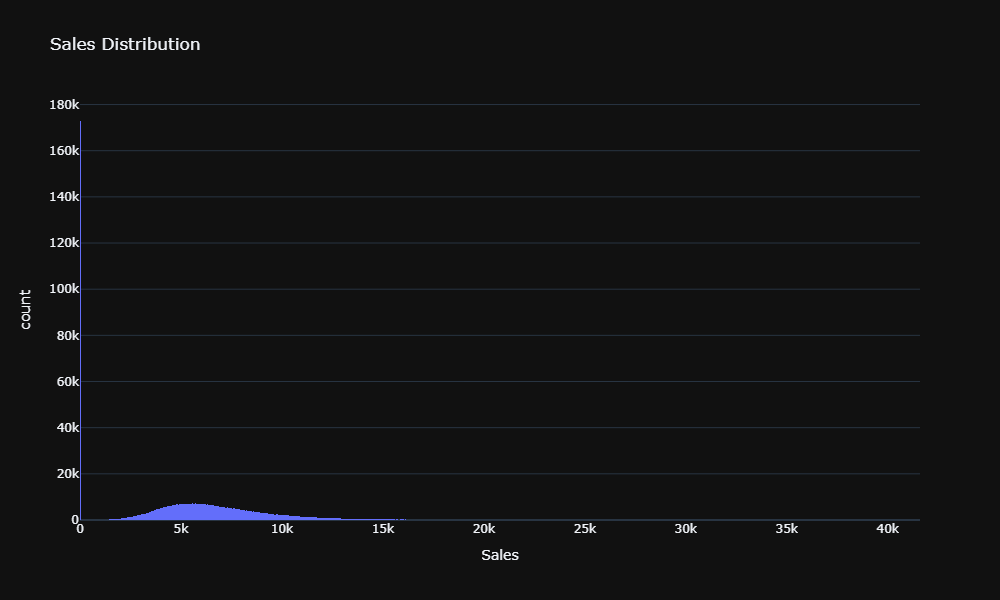

In [169]:
# Since there are many 0 sales (reason might be store close, some holiday or something)
# Therefore it will become difficult for our linear model to catch the pattern (although tree based model can do but they can overfit to train dataset)
# That's why its good idea to remove the close store(0) enteries. 
px.histogram(merged_df, x='Sales', title='Sales Distribution', template='plotly_dark', height=600, width=1000)

In [170]:
# There are 172817 enteries when store was closed and almost same 0 sales enteries.
display(merged_df.Open.value_counts())
display(merged_df.Sales.value_counts())

Open
1    844392
0    172817
Name: count, dtype: int64

Sales
0        172871
5674        215
5558        197
5483        196
6049        195
          ...  
20050         1
1067          1
660           1
17815         1
23303         1
Name: count, Length: 21734, dtype: int64

In [171]:
# Excluding closed store enteries.
merged_df = merged_df[merged_df.Open == 1]
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Day,Month,Year,WeekOfYear
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,9.0,2008.0,0,0.0,0.0,None,31,7,2015,31
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",31,7,2015,31
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",31,7,2015,31
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,9.0,2009.0,0,0.0,0.0,None,31,7,2015,31
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,4.0,2015.0,0,0.0,0.0,None,31,7,2015,31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016776,682,2,2013-01-01,3375,566,1,0,a,1,b,...,9.0,2006.0,0,0.0,0.0,None,1,1,2013,1
1016827,733,2,2013-01-01,10765,2377,1,0,a,1,b,...,10.0,1999.0,0,0.0,0.0,None,1,1,2013,1
1016863,769,2,2013-01-01,5035,1248,1,0,a,1,b,...,0.0,0.0,1,48.0,2012.0,"Jan,Apr,Jul,Oct",1,1,2013,1
1017042,948,2,2013-01-01,4491,1039,1,0,a,1,b,...,0.0,0.0,0,0.0,0.0,None,1,1,2013,1


In [172]:
# Now there are only 54 enteries for 0 sales.
merged_df.Sales.value_counts()[0]

np.int64(54)

In [173]:
merged_test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Id                         41088 non-null  int64         
 1   Store                      41088 non-null  int64         
 2   DayOfWeek                  41088 non-null  int64         
 3   Date                       41088 non-null  datetime64[us]
 4   Open                       41088 non-null  float64       
 5   Promo                      41088 non-null  int64         
 6   StateHoliday               41088 non-null  str           
 7   SchoolHoliday              41088 non-null  int64         
 8   StoreType                  41088 non-null  str           
 9   Assortment                 41088 non-null  str           
 10  CompetitionDistance        40992 non-null  float64       
 11  CompetitionOpenSinceMonth  41088 non-null  float64       
 12  CompetitionOpen

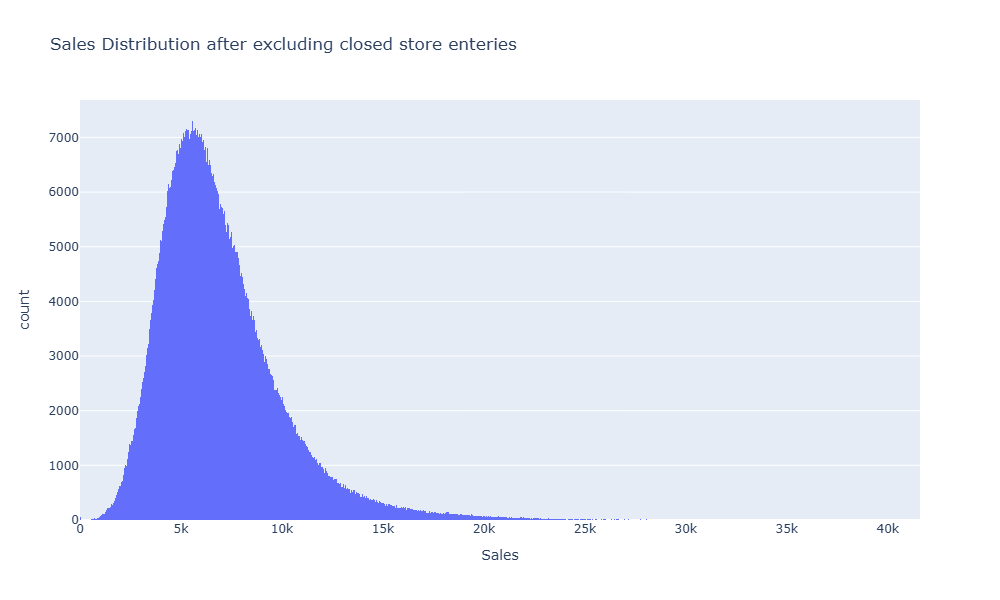

In [174]:
# Now it looks smooth.
px.histogram(merged_df, x='Sales', title='Sales Distribution after excluding closed store enteries',  template='plotly', height=600, width=1000)

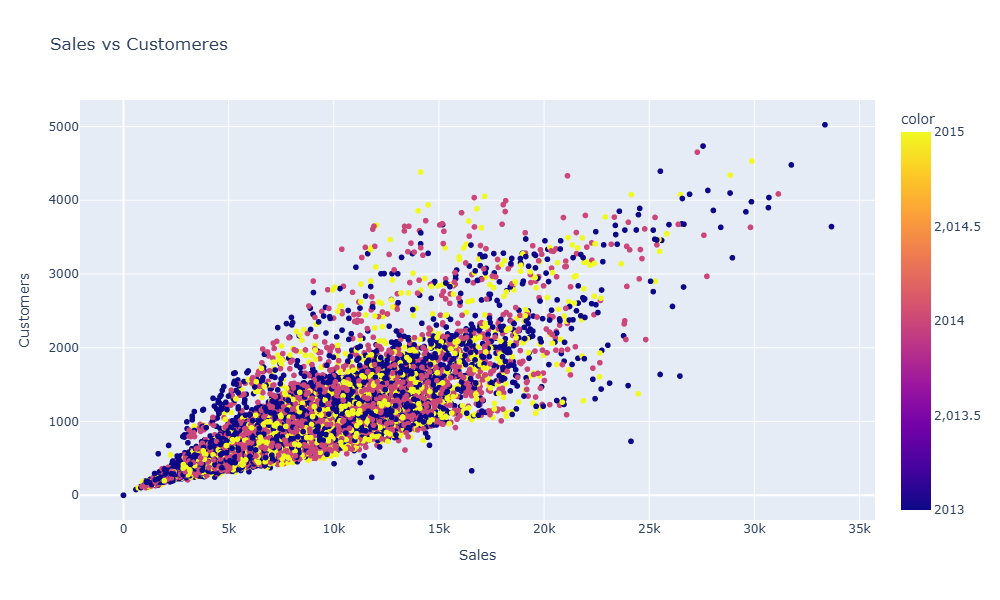

In [175]:
temp_df = merged_df.sample(40000)
fig = px.scatter(
    temp_df, 
    x='Sales', 
    y='Customers', 
    title='Sales vs Customeres',
    color=temp_df.Date.dt.year
    
)
fig.update_layout(
    template='plotly', 
    height=600, 
    width=1000
)
fig.show()

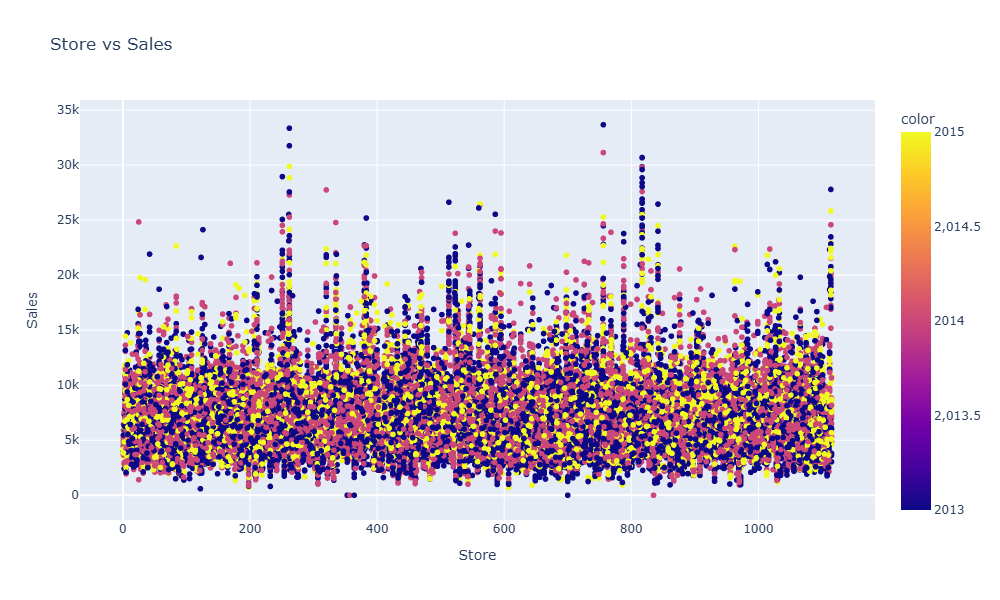

In [176]:
fig = px.scatter(
    temp_df, 
    x='Store', 
    y='Sales', 
    title='Store vs Sales',
    color=temp_df.Date.dt.year
    
)
fig.update_layout(
    template='plotly', 
    height=600, 
    width=1000
)
fig.show()

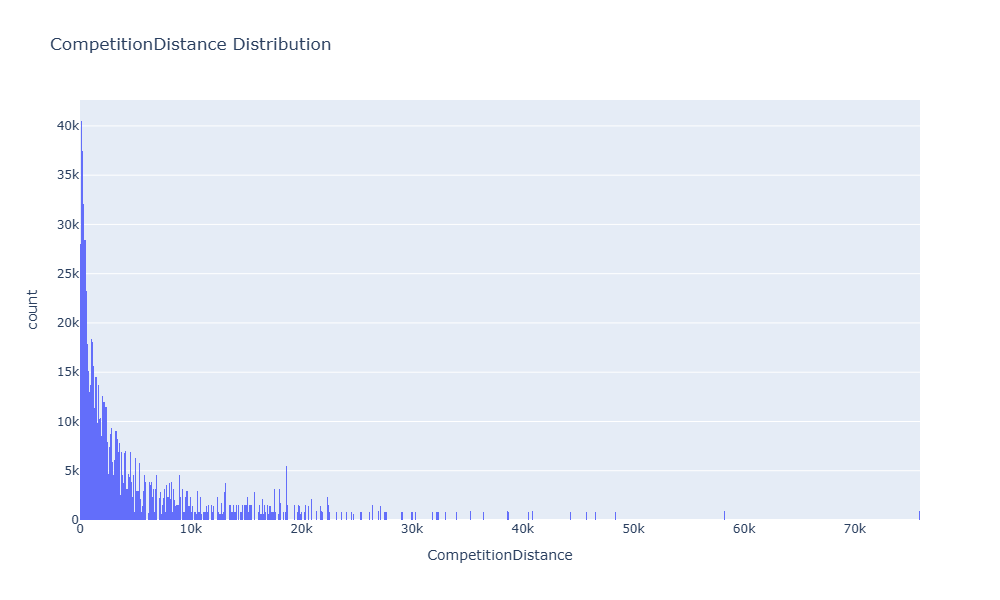

In [177]:
fig = px.histogram(
    merged_df, 
    x='CompetitionDistance',
    title='CompetitionDistance Distribution'
    
)
fig.update_layout(
    template='plotly', 
    height=600, 
    width=1000
)
fig.show()

Text(0.5, 1.0, 'DayOfWeek vs Sales')

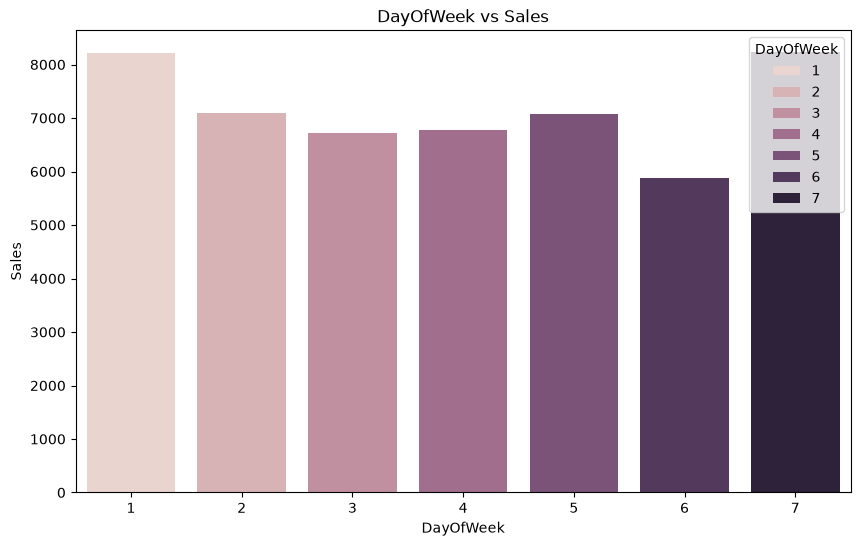

In [178]:
plt.figure(figsize=(10,6))
sns.barplot(merged_df, x='DayOfWeek', y='Sales', hue='DayOfWeek', errorbar=None)
plt.title('DayOfWeek vs Sales')

Text(0.5, 1.0, 'Promo vs Sales')

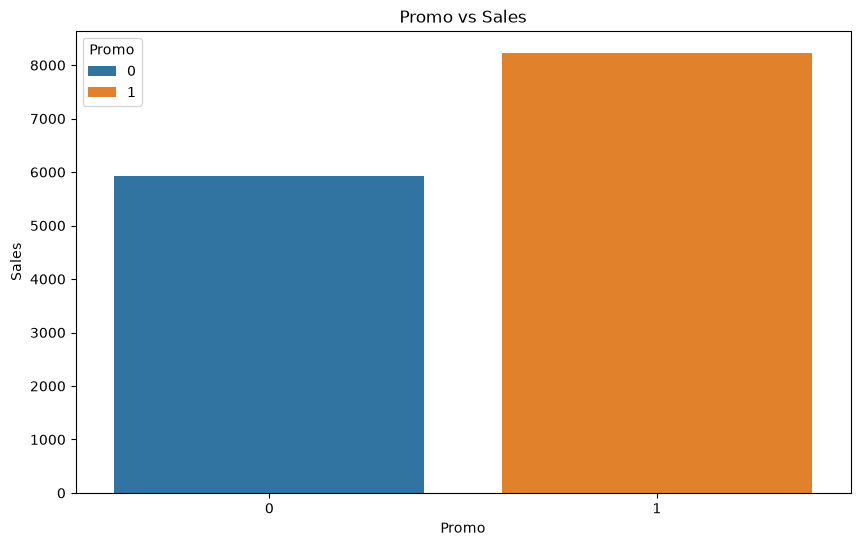

In [179]:
plt.figure(figsize=(10,6))
sns.barplot(merged_df, x='Promo', y='Sales', hue='Promo', errorbar=None)
plt.title('Promo vs Sales')

Text(0.5, 1.0, 'Promo2 vs Sales')

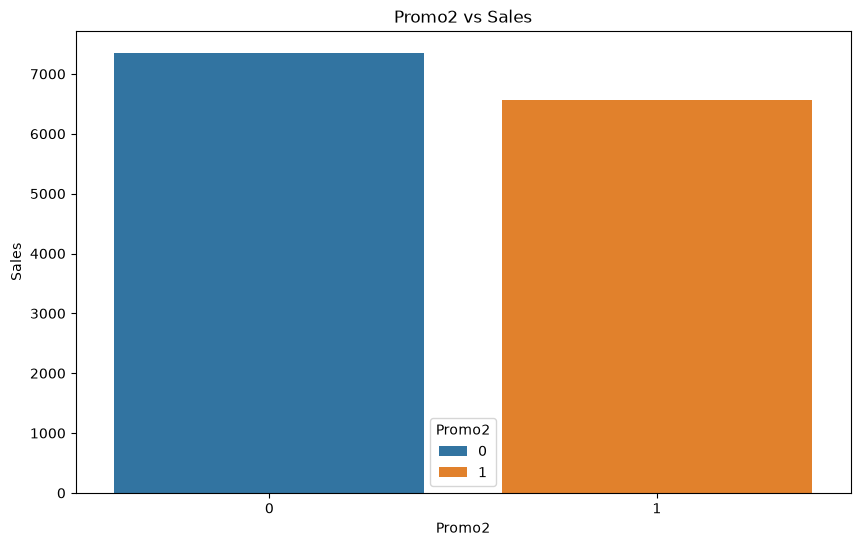

In [180]:
plt.figure(figsize=(10,6))
sns.barplot(merged_df, x='Promo2', y='Sales', hue='Promo2', errorbar=None)
plt.title('Promo2 vs Sales')

In [181]:
merged_df.corr(numeric_only=True).Sales.sort_values(ascending=False)

Sales                        1.000000
Customers                    0.823597
Promo                        0.368145
WeekOfYear                   0.074472
Month                        0.073600
SchoolHoliday                0.038617
Year                         0.036169
Store                        0.007710
CompetitionOpenSinceYear     0.005266
CompetitionOpenSinceMonth   -0.018370
CompetitionDistance         -0.036396
Day                         -0.051849
Promo2SinceWeek             -0.058476
Promo2                      -0.127596
Promo2SinceYear             -0.127621
DayOfWeek                   -0.178736
Open                              NaN
Name: Sales, dtype: float64

Text(0.5, 1.0, 'Sales Correlaiton Matrix')

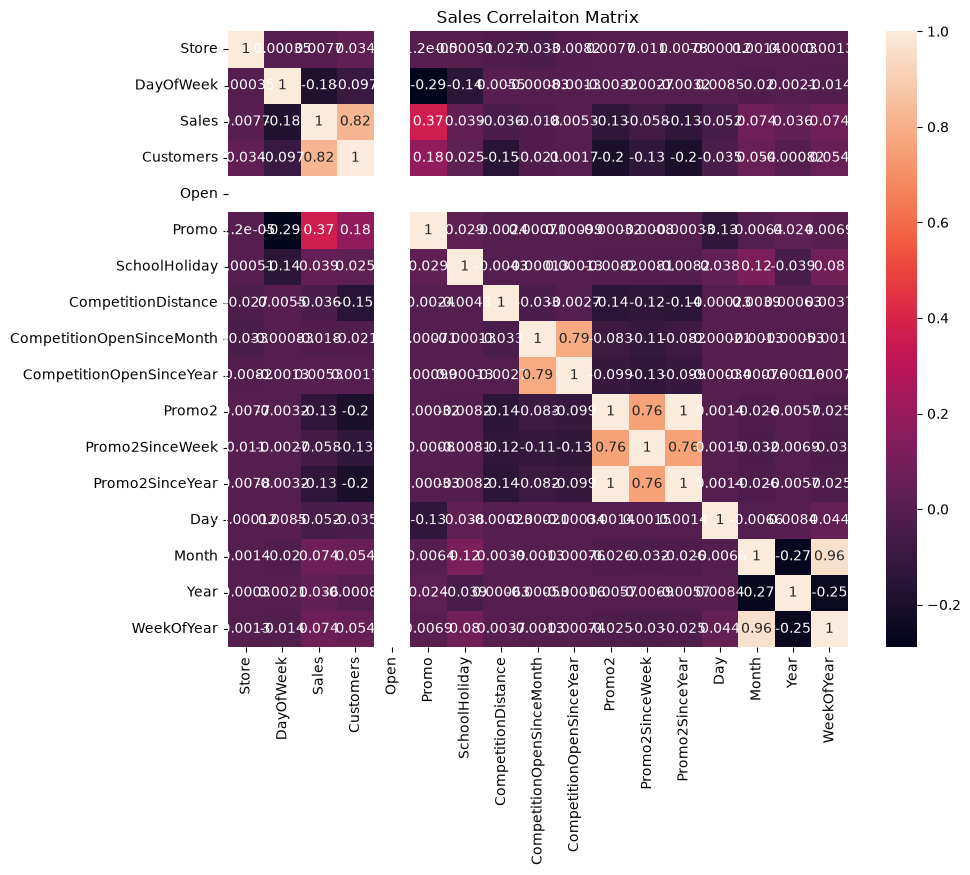

In [182]:
plt.figure(figsize=(10,8))
sns.heatmap(merged_df.corr(numeric_only=True), annot=True)
plt.title('Sales Correlaiton Matrix')

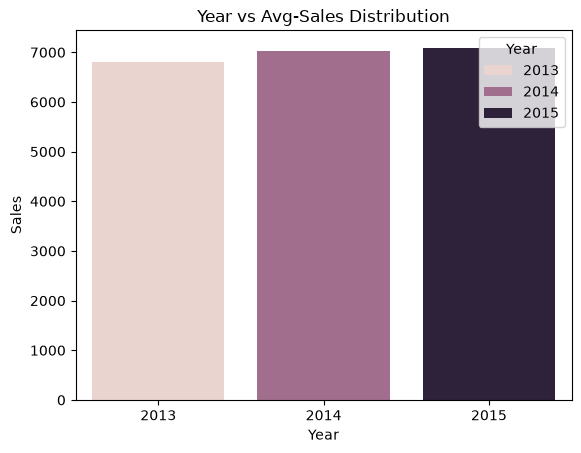

In [183]:
sns.barplot(merged_df, x='Year', y='Sales', hue='Year', errorbar=None)
plt.title('Year vs Avg-Sales Distribution')
plt.show()

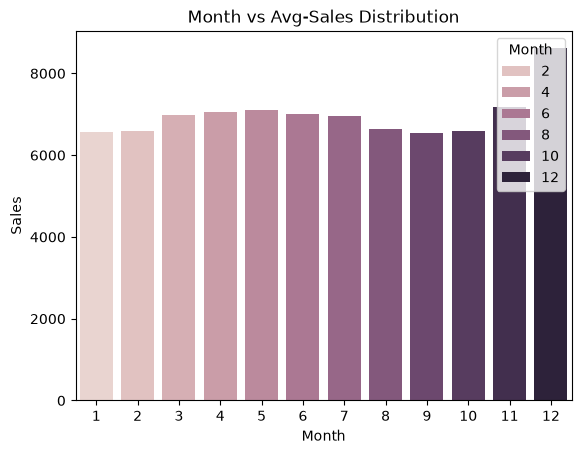

In [184]:
sns.barplot(merged_df, x='Month', y='Sales', hue='Month', errorbar=None)
plt.title('Month vs Avg-Sales Distribution')
plt.show()

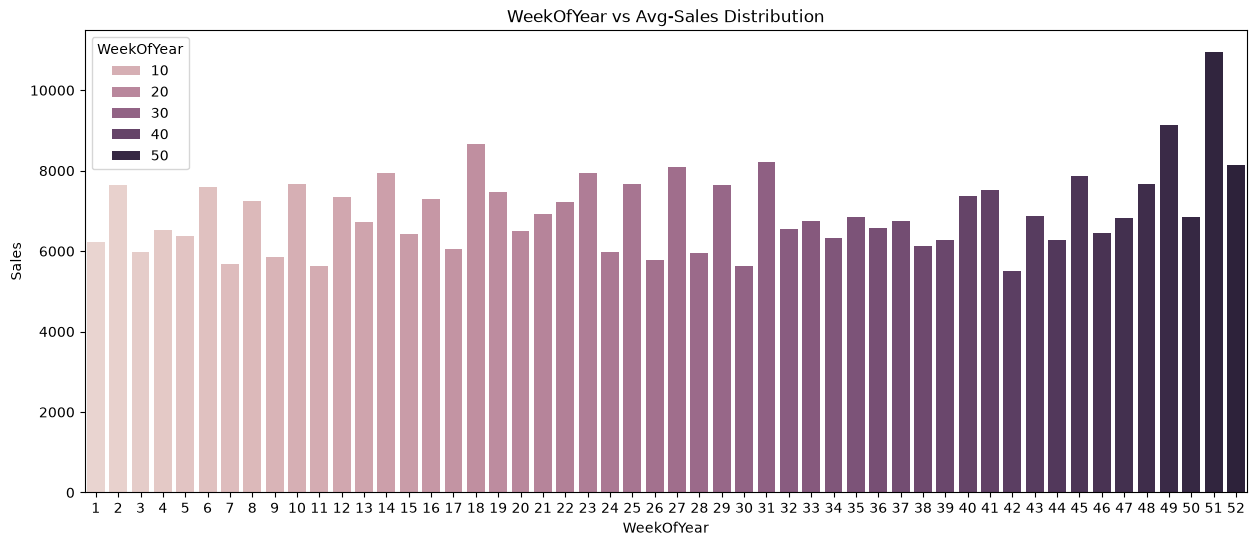

In [185]:
plt.figure(figsize=(15,6))
sns.barplot(merged_df, x='WeekOfYear', y='Sales', hue='WeekOfYear', errorbar=None)
plt.title('WeekOfYear vs Avg-Sales Distribution')
plt.show()

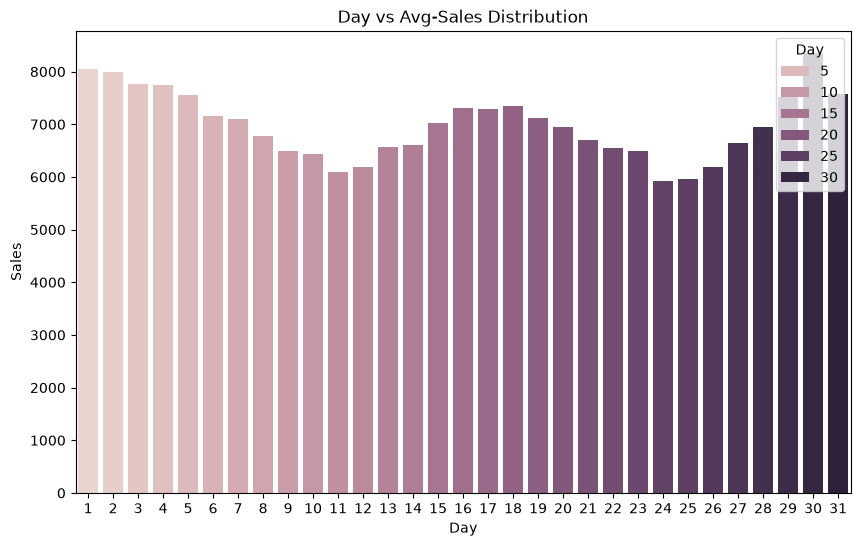

In [186]:
plt.figure(figsize=(10,6))
sns.barplot(merged_df, x='Day', y='Sales', hue='Day', errorbar=None)
plt.title('Day vs Avg-Sales Distribution')
plt.show()

In [187]:
display(merged_df.CompetitionDistance.mean())
display(merged_df.CompetitionDistance.median())

np.float64(5457.979627312083)

np.float64(2320.0)

## Data Preparation

### Train/Test/Validation Split

In [188]:
size = len(merged_df)
size

844392

In [189]:
split = int(0.75 * size)
split

633294

In [190]:
sorted_df = merged_df.sort_values('Date', ignore_index=True)
sorted_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Day,Month,Year,WeekOfYear
0,1097,2,2013-01-01,5961,1405,1,0,a,1,b,...,3.0,2002.0,0,0.0,0.0,None,1,1,2013,1
1,85,2,2013-01-01,4220,619,1,0,a,1,b,...,10.0,2011.0,0,0.0,0.0,None,1,1,2013,1
2,259,2,2013-01-01,6851,1444,1,0,a,1,b,...,0.0,0.0,0,0.0,0.0,None,1,1,2013,1
3,262,2,2013-01-01,17267,2875,1,0,a,1,b,...,5.0,2013.0,0,0.0,0.0,None,1,1,2013,1
4,274,2,2013-01-01,3102,729,1,0,a,1,b,...,0.0,0.0,1,10.0,2013.0,"Jan,Apr,Jul,Oct",1,1,2013,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
844387,745,5,2015-07-31,8363,746,1,1,0,1,a,...,11.0,2013.0,1,37.0,2009.0,"Jan,Apr,Jul,Oct",31,7,2015,31
844388,746,5,2015-07-31,9082,638,1,1,0,1,d,...,2.0,2011.0,1,35.0,2011.0,"Mar,Jun,Sept,Dec",31,7,2015,31
844389,747,5,2015-07-31,10708,826,1,1,0,1,c,...,8.0,2008.0,0,0.0,0.0,None,31,7,2015,31
844390,741,5,2015-07-31,11253,1137,1,1,0,1,d,...,0.0,0.0,0,0.0,0.0,None,31,7,2015,31


In [86]:
# Spliting in 25, 75 ratio.
train_df, val_df = sorted_df[:split], sorted_df[split:]

In [87]:
train_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Day,Month,Year,WeekOfYear
0,1097,2,2013-01-01,5961,1405,1,0,a,1,b,...,3.0,2002.0,0,0.0,0.0,None,1,1,2013,1
1,85,2,2013-01-01,4220,619,1,0,a,1,b,...,10.0,2011.0,0,0.0,0.0,None,1,1,2013,1
2,259,2,2013-01-01,6851,1444,1,0,a,1,b,...,0.0,0.0,0,0.0,0.0,None,1,1,2013,1
3,262,2,2013-01-01,17267,2875,1,0,a,1,b,...,5.0,2013.0,0,0.0,0.0,None,1,1,2013,1
4,274,2,2013-01-01,3102,729,1,0,a,1,b,...,0.0,0.0,1,10.0,2013.0,"Jan,Apr,Jul,Oct",1,1,2013,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633289,745,3,2014-12-10,6897,657,1,0,0,0,a,...,11.0,2013.0,1,37.0,2009.0,"Jan,Apr,Jul,Oct",10,12,2014,50
633290,756,3,2014-12-10,15736,2292,1,0,0,0,a,...,0.0,0.0,1,40.0,2011.0,"Jan,Apr,Jul,Oct",10,12,2014,50
633291,747,3,2014-12-10,7444,608,1,0,0,0,c,...,8.0,2008.0,0,0.0,0.0,None,10,12,2014,50
633292,746,3,2014-12-10,5207,474,1,0,0,0,d,...,2.0,2011.0,1,35.0,2011.0,"Mar,Jun,Sept,Dec",10,12,2014,50


In [88]:
val_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Day,Month,Year,WeekOfYear
633294,751,3,2014-12-10,3720,533,1,0,0,0,a,...,10.0,2006.0,0,0.0,0.0,None,10,12,2014,50
633295,752,3,2014-12-10,4258,404,1,0,0,0,a,...,3.0,2013.0,1,31.0,2013.0,"Feb,May,Aug,Nov",10,12,2014,50
633296,753,3,2014-12-10,7170,654,1,0,0,0,d,...,11.0,2012.0,1,35.0,2010.0,"Mar,Jun,Sept,Dec",10,12,2014,50
633297,754,3,2014-12-10,7359,837,1,0,0,0,c,...,5.0,2008.0,1,10.0,2014.0,"Mar,Jun,Sept,Dec",10,12,2014,50
633298,748,3,2014-12-10,4579,411,1,0,0,0,d,...,3.0,2010.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",10,12,2014,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
844387,745,5,2015-07-31,8363,746,1,1,0,1,a,...,11.0,2013.0,1,37.0,2009.0,"Jan,Apr,Jul,Oct",31,7,2015,31
844388,746,5,2015-07-31,9082,638,1,1,0,1,d,...,2.0,2011.0,1,35.0,2011.0,"Mar,Jun,Sept,Dec",31,7,2015,31
844389,747,5,2015-07-31,10708,826,1,1,0,1,c,...,8.0,2008.0,0,0.0,0.0,None,31,7,2015,31
844390,741,5,2015-07-31,11253,1137,1,1,0,1,d,...,0.0,0.0,0,0.0,0.0,None,31,7,2015,31


In [89]:
display(merged_test_df.columns)
len(merged_test_df.columns)

Index(['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday',
       'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance',
       'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2',
       'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'Day', 'Month',
       'Year', 'WeekOfYear'],
      dtype='str')

21

In [90]:
cols = train_df.columns
input_cols = [col for col in cols if col not in ['Date', 'Sales']]
display(input_cols)
len(input_cols)

['Store',
 'DayOfWeek',
 'Customers',
 'Open',
 'Promo',
 'StateHoliday',
 'SchoolHoliday',
 'StoreType',
 'Assortment',
 'CompetitionDistance',
 'CompetitionOpenSinceMonth',
 'CompetitionOpenSinceYear',
 'Promo2',
 'Promo2SinceWeek',
 'Promo2SinceYear',
 'PromoInterval',
 'Day',
 'Month',
 'Year',
 'WeekOfYear']

20

In [91]:
train_df[input_cols].nunique()

Store                        1115
DayOfWeek                       7
Customers                    3966
Open                            1
Promo                           2
StateHoliday                    4
SchoolHoliday                   2
StoreType                       4
Assortment                      3
CompetitionDistance           654
CompetitionOpenSinceMonth      13
CompetitionOpenSinceYear       24
Promo2                          2
Promo2SinceWeek                25
Promo2SinceYear                 8
PromoInterval                   4
Day                            31
Month                          12
Year                            2
WeekOfYear                     52
dtype: int64

In [92]:
target_cols = 'Sales'
merged_df[target_cols]

0           5263
1           6064
2           8314
3          13995
4           4822
           ...  
1016776     3375
1016827    10765
1016863     5035
1017042     4491
1017190     5961
Name: Sales, Length: 844392, dtype: int64

In [93]:
numeric_cols = ['Store', 'CompetitionDistance', 'Day', 'Month', 'Year', 'WeekOfYear']
categorical_cols = ['DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment','Promo2', 'PromoInterval']
categorical_cols

['DayOfWeek',
 'Open',
 'Promo',
 'StateHoliday',
 'SchoolHoliday',
 'StoreType',
 'Assortment',
 'Promo2',
 'PromoInterval']

### Missing value imputation

In [102]:
from sklearn.impute import SimpleImputer

# Since Only CompetitionDistance need imputation and mean is highly influenced by outliers.
# Therefore, we are using median strategy here.
imputer = SimpleImputer(strategy='median')
imputer.fit(train_df[numeric_cols])

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['Store','CompetitionDistance','Day','Month','Year','WeekOfYear']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](6,)","[ 558.,2330., 16., 6.,2013., 25.]"


In [103]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 633294 entries, 0 to 633293
Data columns (total 22 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   Store                      633294 non-null  int64         
 1   DayOfWeek                  633294 non-null  int64         
 2   Date                       633294 non-null  datetime64[us]
 3   Sales                      633294 non-null  int64         
 4   Customers                  633294 non-null  int64         
 5   Open                       633294 non-null  int64         
 6   Promo                      633294 non-null  int64         
 7   StateHoliday               633294 non-null  str           
 8   SchoolHoliday              633294 non-null  int64         
 9   StoreType                  633294 non-null  str           
 10  Assortment                 633294 non-null  str           
 11  CompetitionDistance        631666 non-null  float64       
 12 

In [104]:
train_df.loc[train_df.CompetitionDistance.isna(), 'CompetitionDistance']

113      NaN
698      NaN
960      NaN
1223     NaN
1808     NaN
          ..
631287   NaN
631511   NaN
632224   NaN
632444   NaN
633157   NaN
Name: CompetitionDistance, Length: 1628, dtype: float64

In [105]:

train_df[numeric_cols] = imputer.transform(train_df[numeric_cols])
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 633294 entries, 0 to 633293
Data columns (total 22 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   Store                      633294 non-null  float64       
 1   DayOfWeek                  633294 non-null  int64         
 2   Date                       633294 non-null  datetime64[us]
 3   Sales                      633294 non-null  int64         
 4   Customers                  633294 non-null  int64         
 5   Open                       633294 non-null  int64         
 6   Promo                      633294 non-null  int64         
 7   StateHoliday               633294 non-null  str           
 8   SchoolHoliday              633294 non-null  int64         
 9   StoreType                  633294 non-null  str           
 10  Assortment                 633294 non-null  str           
 11  CompetitionDistance        633294 non-null  float64       
 12 

In [106]:
val_df[numeric_cols] = imputer.transform(val_df[numeric_cols])
val_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 211098 entries, 633294 to 844391
Data columns (total 22 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   Store                      211098 non-null  float64       
 1   DayOfWeek                  211098 non-null  int64         
 2   Date                       211098 non-null  datetime64[us]
 3   Sales                      211098 non-null  int64         
 4   Customers                  211098 non-null  int64         
 5   Open                       211098 non-null  int64         
 6   Promo                      211098 non-null  int64         
 7   StateHoliday               211098 non-null  str           
 8   SchoolHoliday              211098 non-null  int64         
 9   StoreType                  211098 non-null  str           
 10  Assortment                 211098 non-null  str           
 11  CompetitionDistance        211098 non-null  float64       

In [107]:
merged_test_df[numeric_cols] = imputer.transform(merged_test_df[numeric_cols])
merged_test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Id                         41088 non-null  int64         
 1   Store                      41088 non-null  float64       
 2   DayOfWeek                  41088 non-null  int64         
 3   Date                       41088 non-null  datetime64[us]
 4   Open                       41088 non-null  float64       
 5   Promo                      41088 non-null  int64         
 6   StateHoliday               41088 non-null  str           
 7   SchoolHoliday              41088 non-null  int64         
 8   StoreType                  41088 non-null  str           
 9   Assortment                 41088 non-null  str           
 10  CompetitionDistance        41088 non-null  float64       
 11  CompetitionOpenSinceMonth  41088 non-null  float64       
 12  CompetitionOpen

### Encoding categorical columns

In [108]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore')
encoder.fit(train_df[categorical_cols])
encoded_cols = list(encoder.get_feature_names_out(categorical_cols))
encoded_cols

['DayOfWeek_1',
 'DayOfWeek_2',
 'DayOfWeek_3',
 'DayOfWeek_4',
 'DayOfWeek_5',
 'DayOfWeek_6',
 'DayOfWeek_7',
 'Open_1',
 'Promo_0',
 'Promo_1',
 'StateHoliday_0',
 'StateHoliday_a',
 'StateHoliday_b',
 'StateHoliday_c',
 'SchoolHoliday_0',
 'SchoolHoliday_1',
 'StoreType_a',
 'StoreType_b',
 'StoreType_c',
 'StoreType_d',
 'Assortment_a',
 'Assortment_b',
 'Assortment_c',
 'Promo2_0',
 'Promo2_1',
 'PromoInterval_Feb,May,Aug,Nov',
 'PromoInterval_Jan,Apr,Jul,Oct',
 'PromoInterval_Mar,Jun,Sept,Dec',
 'PromoInterval_None']

In [109]:
train_df[encoded_cols] = encoder.transform(train_df[categorical_cols]).toarray()
train_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,StoreType_d,Assortment_a,Assortment_b,Assortment_c,Promo2_0,Promo2_1,"PromoInterval_Feb,May,Aug,Nov","PromoInterval_Jan,Apr,Jul,Oct","PromoInterval_Mar,Jun,Sept,Dec",PromoInterval_None
0,1097.0,2,2013-01-01,5961,1405,1,0,a,1,b,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,85.0,2,2013-01-01,4220,619,1,0,a,1,b,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,259.0,2,2013-01-01,6851,1444,1,0,a,1,b,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,262.0,2,2013-01-01,17267,2875,1,0,a,1,b,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,274.0,2,2013-01-01,3102,729,1,0,a,1,b,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633289,745.0,3,2014-12-10,6897,657,1,0,0,0,a,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
633290,756.0,3,2014-12-10,15736,2292,1,0,0,0,a,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
633291,747.0,3,2014-12-10,7444,608,1,0,0,0,c,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
633292,746.0,3,2014-12-10,5207,474,1,0,0,0,d,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0


In [110]:
val_df[encoded_cols] = encoder.transform(val_df[categorical_cols]).toarray()
val_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,StoreType_d,Assortment_a,Assortment_b,Assortment_c,Promo2_0,Promo2_1,"PromoInterval_Feb,May,Aug,Nov","PromoInterval_Jan,Apr,Jul,Oct","PromoInterval_Mar,Jun,Sept,Dec",PromoInterval_None
633294,751.0,3,2014-12-10,3720,533,1,0,0,0,a,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
633295,752.0,3,2014-12-10,4258,404,1,0,0,0,a,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
633296,753.0,3,2014-12-10,7170,654,1,0,0,0,d,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
633297,754.0,3,2014-12-10,7359,837,1,0,0,0,c,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
633298,748.0,3,2014-12-10,4579,411,1,0,0,0,d,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
844387,745.0,5,2015-07-31,8363,746,1,1,0,1,a,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
844388,746.0,5,2015-07-31,9082,638,1,1,0,1,d,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
844389,747.0,5,2015-07-31,10708,826,1,1,0,1,c,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
844390,741.0,5,2015-07-31,11253,1137,1,1,0,1,d,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


In [111]:
merged_test_df[encoded_cols] = encoder.transform(merged_test_df[categorical_cols]).toarray()
merged_test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,StoreType_d,Assortment_a,Assortment_b,Assortment_c,Promo2_0,Promo2_1,"PromoInterval_Feb,May,Aug,Nov","PromoInterval_Jan,Apr,Jul,Oct","PromoInterval_Mar,Jun,Sept,Dec",PromoInterval_None
0,1,1.0,4,2015-09-17,1.0,1,0,0,c,a,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,2,3.0,4,2015-09-17,1.0,1,0,0,a,a,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,3,7.0,4,2015-09-17,1.0,1,0,0,a,c,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3,4,8.0,4,2015-09-17,1.0,1,0,0,a,a,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,5,9.0,4,2015-09-17,1.0,1,0,0,a,c,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111.0,6,2015-08-01,1.0,0,0,0,a,a,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
41084,41085,1112.0,6,2015-08-01,1.0,0,0,0,c,c,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
41085,41086,1113.0,6,2015-08-01,1.0,0,0,0,a,c,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
41086,41087,1114.0,6,2015-08-01,1.0,0,0,0,a,c,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


### Scaling Numerical Columns

In [112]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(train_df[numeric_cols])

StandardScaler()

In [113]:
train_df[numeric_cols] = scaler.transform(train_df[numeric_cols])
val_df[numeric_cols] = scaler.transform(val_df[numeric_cols])
merged_test_df[numeric_cols] = scaler.transform(merged_test_df[numeric_cols])

In [114]:
train_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,StoreType_d,Assortment_a,Assortment_b,Assortment_c,Promo2_0,Promo2_1,"PromoInterval_Feb,May,Aug,Nov","PromoInterval_Jan,Apr,Jul,Oct","PromoInterval_Mar,Jun,Sept,Dec",PromoInterval_None
0,1.673920,2,2013-01-01,5961,1405,1,0,a,1,b,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,-1.471791,2,2013-01-01,4220,619,1,0,a,1,b,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.930928,2,2013-01-01,6851,1444,1,0,a,1,b,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,-0.921603,2,2013-01-01,17267,2875,1,0,a,1,b,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,-0.884302,2,2013-01-01,3102,729,1,0,a,1,b,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633289,0.579760,3,2014-12-10,6897,657,1,0,0,0,a,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
633290,0.613952,3,2014-12-10,15736,2292,1,0,0,0,a,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
633291,0.585977,3,2014-12-10,7444,608,1,0,0,0,c,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
633292,0.582868,3,2014-12-10,5207,474,1,0,0,0,d,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0


### Extracting Required Features for model training.

In [115]:
X_train = train_df[numeric_cols + encoded_cols]
X_val = val_df[numeric_cols + encoded_cols]
X_test = merged_test_df[numeric_cols + encoded_cols]

In [116]:
# We don't have test targets, we have to directly submit to kaggle page.
Y_train = train_df['Sales']
Y_val = val_df['Sales']

## Baseline Model

### Fixed value model

In [117]:
def return_mean(inputs):
    return np.full(len(inputs), np.mean(inputs))

train_preds = return_mean(Y_train)
train_preds

array([6873.17964168, 6873.17964168, 6873.17964168, ..., 6873.17964168,
       6873.17964168, 6873.17964168], shape=(633294,))

In [118]:
from sklearn.metrics import root_mean_squared_error

# Score is 3081 off, when model predicts each as mean value.
root_mean_squared_error(Y_train, train_preds)

3081.3506358126774

### ML model

In [119]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](35,)","[ 27.38,-186.03, -28.57,..., 201.03,-407.4 , 259.19]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](35,)","['Store','CompetitionDistance','Day',...,'PromoInterval_Jan,Apr,Jul,Oct', 'PromoInterval_Mar,Jun,Sept,Dec','PromoInterval_None']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7053
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,35
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(25)


In [120]:
# Our baseline ml model is very close to our worst score.
train_preds = lin_reg.predict(X_train)
baseline_train_rmse = root_mean_squared_error(Y_train, train_preds)
baseline_train_rmse

2708.818852200152

In [121]:
val_preds = lin_reg.predict(X_val)
baseline_val_rmse = root_mean_squared_error(Y_val, val_preds)
baseline_val_rmse

2784.6899161172787

## Trying different models to evaluate how they perform

In [122]:
def try_model(model):
    model.fit(X_train, Y_train)
    train_rmse = root_mean_squared_error(Y_train, model.predict(X_train))
    val_rmse = root_mean_squared_error(Y_val, model.predict(X_val))
    return f'Algorithm: {model.__class__.__name__} | Train RMSE: {train_rmse} | Val RMSE: {val_rmse}'

### Linear Models

In [123]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor

In [124]:
try_model(LinearRegression())

'Algorithm: LinearRegression | Train RMSE: 2708.818852200152 | Val RMSE: 2784.6899161172787'

In [125]:
try_model(Ridge())

'Algorithm: Ridge | Train RMSE: 2708.8188548890835 | Val RMSE: 2784.6884432159036'

In [126]:
try_model(Lasso())

'Algorithm: Lasso | Train RMSE: 2708.9742929604454 | Val RMSE: 2784.908380255858'

In [127]:
try_model(ElasticNet())

'Algorithm: ElasticNet | Train RMSE: 2844.005670576674 | Val RMSE: 2934.0892791090064'

In [128]:
try_model(SGDRegressor())

'Algorithm: SGDRegressor | Train RMSE: 2709.7339529928568 | Val RMSE: 2792.3705535249655'

### Tree based Models

In [ ]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

# As we can see decisiontree is performing significantly better than linear models.
d_tree = DecisionTreeRegressor(random_state=0)
try_model(d_tree)

'Model: DecisionTreeRegressor(random_state=0) | Train RMSE: 0.0 | Val RMSE: 1514.2692371144174'

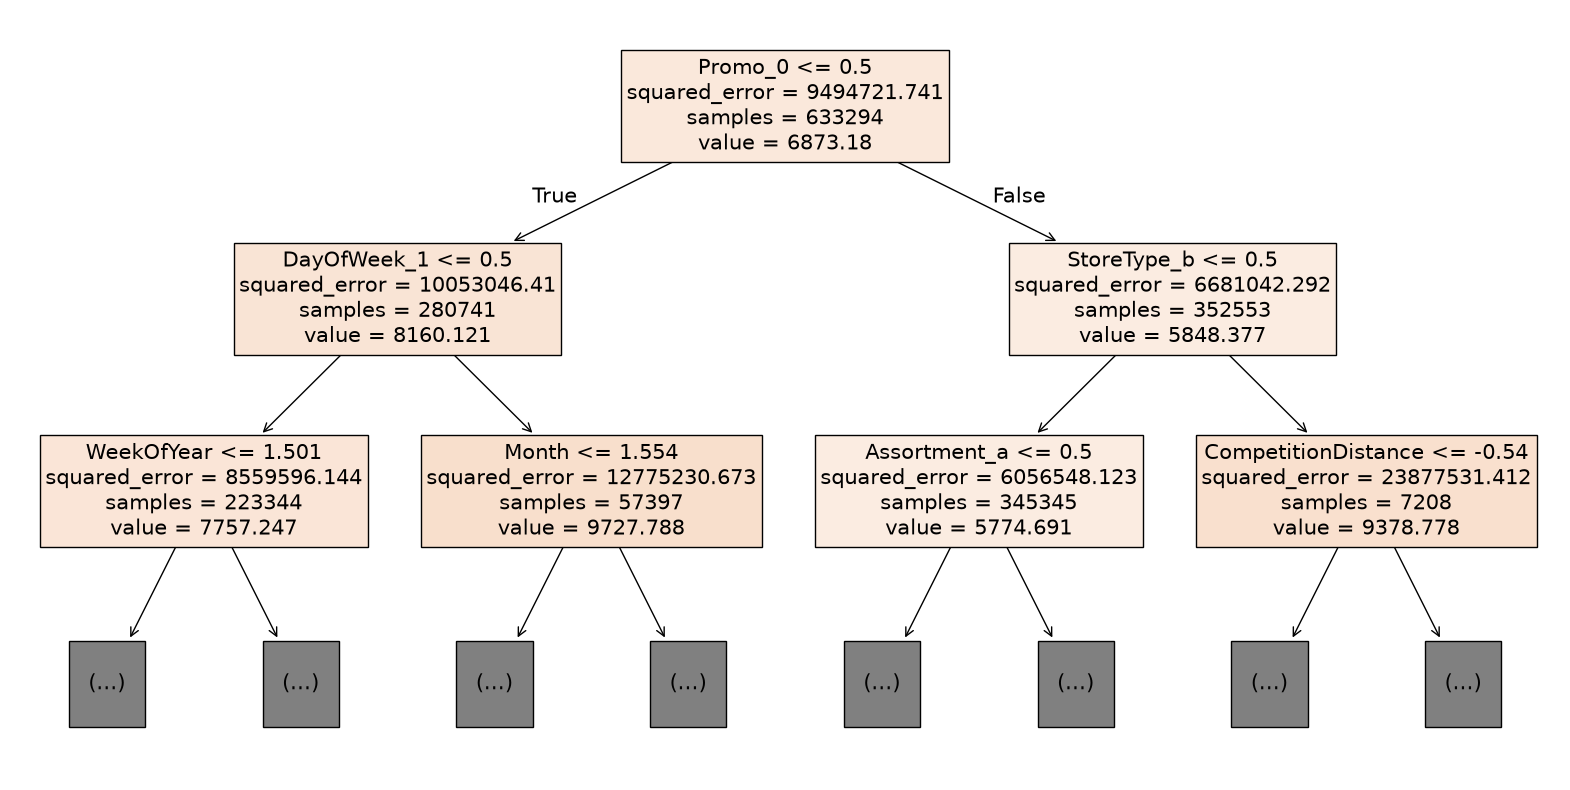

In [ ]:
plt.figure(figsize=(20,10))
plot_tree(d_tree, max_depth=2, filled=True, feature_names=numeric_cols+encoded_cols, fontsize=15)
plt.show()

In [ ]:
importance_df = pd.DataFrame(
    {
        'feature': numeric_cols + encoded_cols,
        'importance': d_tree.feature_importances_
    }
).sort_values('importance', ascending=False, ignore_index=True)
importance_df.head(20)

,feature,importance
0,CompetitionDistance,0.278437
1,Store,0.259178
2,Promo_0,0.138905
3,WeekOfYear,0.044499
4,Day,0.039124
5,DayOfWeek_1,0.032210
6,StoreType_b,0.024806
7,DayOfWeek_6,0.016995
8,Promo2_0,0.016676
9,StoreType_a,0.016571


Text(0.5, 1.0, 'Feature Importance by DecisionTree')

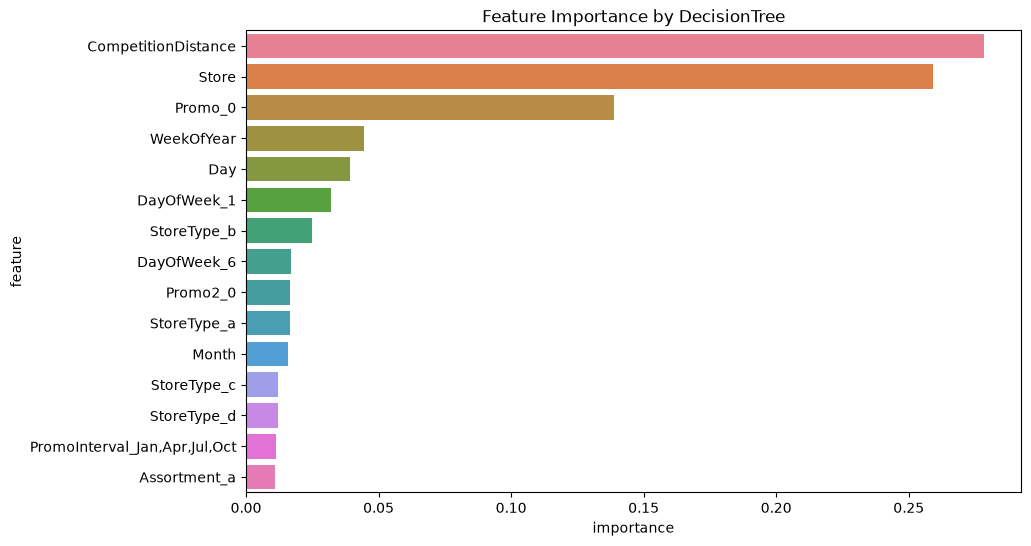

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(importance_df.head(15), x='importance', y='feature', hue='feature')
plt.title('Feature Importance by DecisionTree')

In [129]:
from sklearn.ensemble import RandomForestRegressor

# Hear we got best score so far.
rf = RandomForestRegressor(n_jobs=-1, random_state=0)
try_model(rf)

'Algorithm: RandomForestRegressor | Train RMSE: 346.99134744354285 | Val RMSE: 1249.2271402738195'

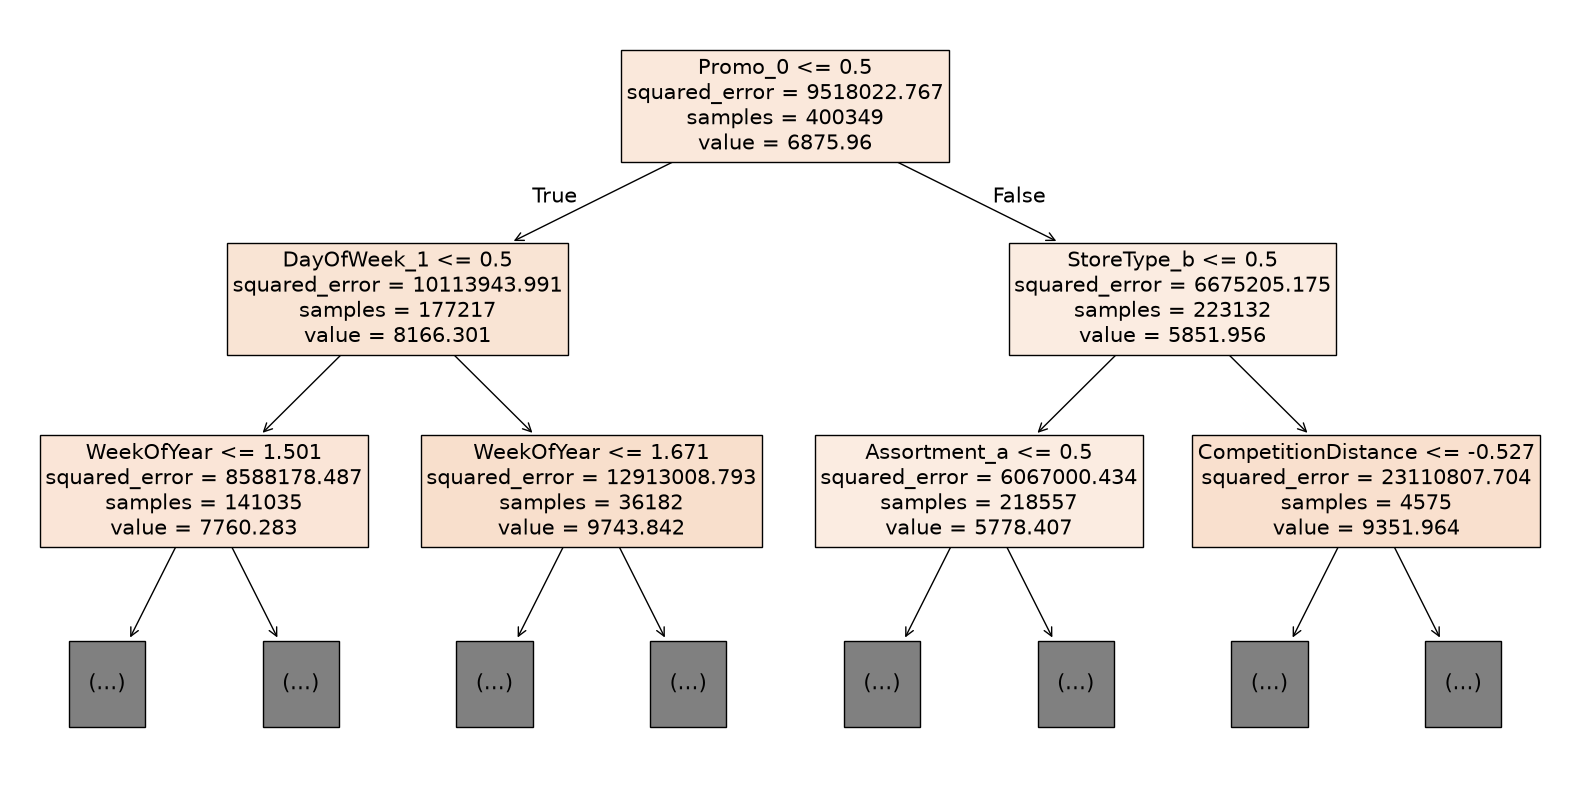

In [ ]:
plt.figure(figsize=(20,10))
plot_tree(rf.estimators_[0], max_depth=2, filled=True, feature_names=numeric_cols+encoded_cols, fontsize=15)
plt.show()

In [ ]:
importance_df = pd.DataFrame(
    {
        'feature': numeric_cols + encoded_cols,
        'importance': rf.feature_importances_
    }
).sort_values('importance', ascending=False, ignore_index=True)
importance_df.head(10)

,feature,importance
0,CompetitionDistance,0.275216
1,Store,0.262920
2,Promo_1,0.076341
3,Promo_0,0.062469
4,WeekOfYear,0.042601
5,Day,0.040248
6,DayOfWeek_1,0.032525
7,StoreType_b,0.024943
8,StoreType_a,0.017041
9,DayOfWeek_6,0.016429


Text(0.5, 1.0, 'Feature Importance by RandomForest')

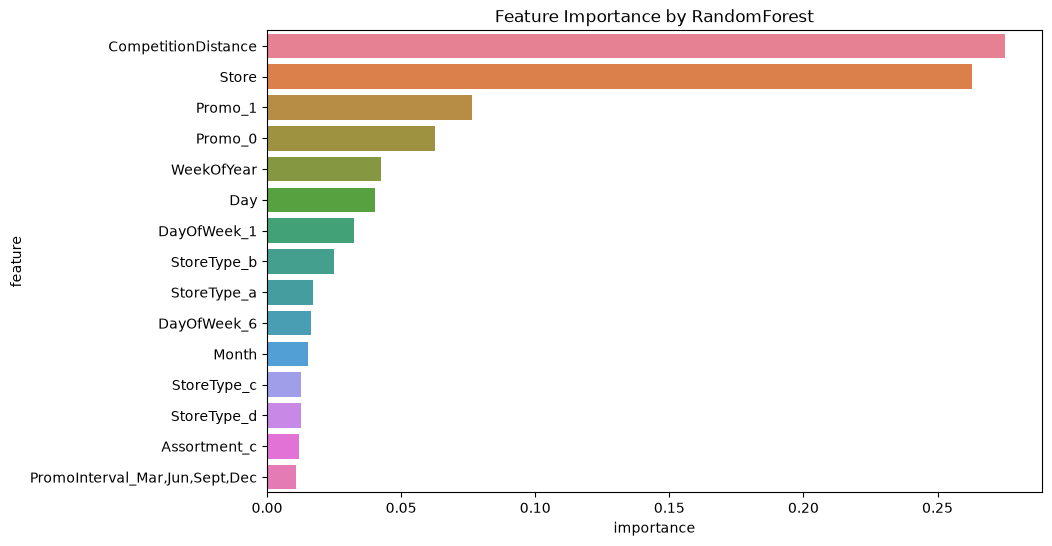

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(importance_df.head(15), x='importance', y='feature', hue='feature')
plt.title('Feature Importance by RandomForest')

### Hyperparameter Tuning on RandonForest

In [ ]:
rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, min_samples_leaf=5, random_state=0, verbose=1)
try_model(rf)

In [ ]:
def sweep(param, values, **fixed):
    for v in values:
        rf = RandomForestRegressor(n_estimators=30, n_jobs=-1, random_state=0, verbose=1,
                                   **{**fixed, param: v})
        rf.fit(X_train, Y_train)
        error = root_mean_squared_error(Y_val, rf.predict(X_val))
        print(f"Validation rmse: {error} for {param} = {v}")

sweep('min_samples_leaf', [1, 2, 3, 5])
sweep('max_features',     [0.3, 0.5, 0.7, 1.0])

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:  3.5min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed:    5.2s finished


Validation rmse: 1264.509394778219 for min_samples_leaf = 1


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:  3.6min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed:    5.2s finished


Validation rmse: 1257.348601907049 for min_samples_leaf = 2


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:  2.5min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed:    4.0s finished


Validation rmse: 1268.6175481880823 for min_samples_leaf = 3


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:  2.1min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed:    2.3s finished


Validation rmse: 1295.863389496835 for min_samples_leaf = 5


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:  1.1min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed:    4.5s finished


Validation rmse: 1307.5471639123243 for max_features = 0.3


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:  1.6min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed:    5.3s finished


Validation rmse: 1253.6469137317574 for max_features = 0.5


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:  2.2min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed:    7.0s finished


Validation rmse: 1240.1460049208733 for max_features = 0.7


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:  2.7min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed:    4.6s finished


Validation rmse: 1264.509394778219 for max_features = 1.0


In [130]:
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.75, n_jobs=-1, verbose=1, random_state=0)
try_model(rf)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:  1.4min
[Parallel(n_jobs=-1)]: Done 192 tasks      | elapsed:  7.3min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  7.9min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   20.1s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:  1.4min
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:  1.5min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   10.8s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:   29.9s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:   30.4s finished


'Algorithm: RandomForestRegressor | Train RMSE: 541.0841259790328 | Val RMSE: 1234.251279722663'

## Looking at individual predictions

In [134]:
def predict_input(model, single_input):
    if single_input['Open'] == 0:
        return 0.
    input_df = pd.DataFrame([single_input])
    input_df['Date'] = pd.to_datetime(input_df.Date)
    input_df['PromoInterval'] = input_df['PromoInterval'].fillna('None').str.strip()
    input_df['Day'] = input_df.Date.dt.day
    input_df['Month'] = input_df.Date.dt.month
    input_df['Year'] = input_df.Date.dt.year
    input_df['WeekOfYear'] = input_df.Date.dt.isocalendar().week.astype(int)
    input_df[numeric_cols] = imputer.transform(input_df[numeric_cols])
    input_df[numeric_cols] = scaler.transform(input_df[numeric_cols])
    input_df[encoded_cols] = encoder.transform(input_df[categorical_cols]).toarray()
    X_input = input_df[numeric_cols + encoded_cols]
    pred = model.predict(X_input)[0]
    return pred

In [132]:
sample_input = {
 'Store': 1,
 'DayOfWeek': 4,
 'Date': '2015-09-17 00:00:00',
 'Open': 1.0,
 'Promo': 1,
 'StateHoliday': '0',
 'SchoolHoliday': 0,
 'StoreType': 'c',
 'Assortment': 'a',
 'CompetitionDistance': 1270.0,
 'CompetitionOpenSinceMonth': 9.0,
 'CompetitionOpenSinceYear': 2008.0,
 'Promo2': 0,
 'Promo2SinceWeek': np.nan,
 'Promo2SinceYear': np.nan,
 'PromoInterval': np.nan}

sample_input

{'Store': 1,
 'DayOfWeek': 4,
 'Date': '2015-09-17 00:00:00',
 'Open': 1.0,
 'Promo': 1,
 'StateHoliday': '0',
 'SchoolHoliday': 0,
 'StoreType': 'c',
 'Assortment': 'a',
 'CompetitionDistance': 1270.0,
 'CompetitionOpenSinceMonth': 9.0,
 'CompetitionOpenSinceYear': 2008.0,
 'Promo2': 0,
 'Promo2SinceWeek': nan,
 'Promo2SinceYear': nan,
 'PromoInterval': nan}

In [135]:
predict_input(rf, sample_input)

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    0.0s finished


np.float64(4363.251986111112)

## Test Predictions

In [136]:
test_preds = rf.predict(X_test)
test_preds

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    3.8s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    8.9s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    9.0s finished


array([ 4363.25198611,  7683.83908532,  8720.21017857, ...,
        6438.05058261, 21002.7955873 ,  6723.05579365], shape=(41088,))

## Submitting test to kaggle

In [137]:
submission_df = pd.read_csv('./rossmann-store-sales/sample_submission.csv')

In [191]:
submission_df['Sales'] = test_preds * merged_test_df['Open'].astype('float')

In [192]:
submission_df.fillna(0, inplace=True)

,Id,Sales
0,1,4363.251986
1,2,7683.839085
2,3,8720.210179
3,4,6732.921264
4,5,6536.630254
...,...,...
41083,41084,3079.033000
41084,41085,8408.939333
41085,41086,6438.050583
41086,41087,21002.795587


In [193]:
submission_df.to_csv('submission.csv', index=None)

In [141]:
!head submission.csv

'head' is not recognized as an internal or external command,
operable program or batch file.


In [142]:
from IPython.display import FileLink
FileLink('submission.csv')

e:\ML Project (Rossmann-Store-Sales)\submission.csv

In [143]:
import joblib

rossmann_data_models = {
    'X_train': X_train,
    'X_val': X_val,
    'X_test': X_test,
    'Y_train': Y_train,
    'Y_val': Y_val,
    'rf': rf,
    'imputer': imputer,
    'scaler': scaler,
    'encoder': encoder,
    'numeric_cols': numeric_cols,
    'categorical_cols': categorical_cols,
    'encoded_cols': encoded_cols
}

joblib.dump(rossmann_data_models, 'rossmann_data_models')

['rossmann_data_models']